In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Контекст

Ты работаешь в продуктовой команде в агрегаторе такси под названием CentralTaxi.

Твоя задача - провести аналитику и сделать бизнес-выводы относительно состояния агрегатора с точки зрения основных метрик.

Импортируй и подготовь для работы файл **taxi_order_list.csv** - в нём содержится информация о заказах нашего агрегатора такси на десятой неделе 2024 года.

Рассмотрим **продуктовую воронку в такси**

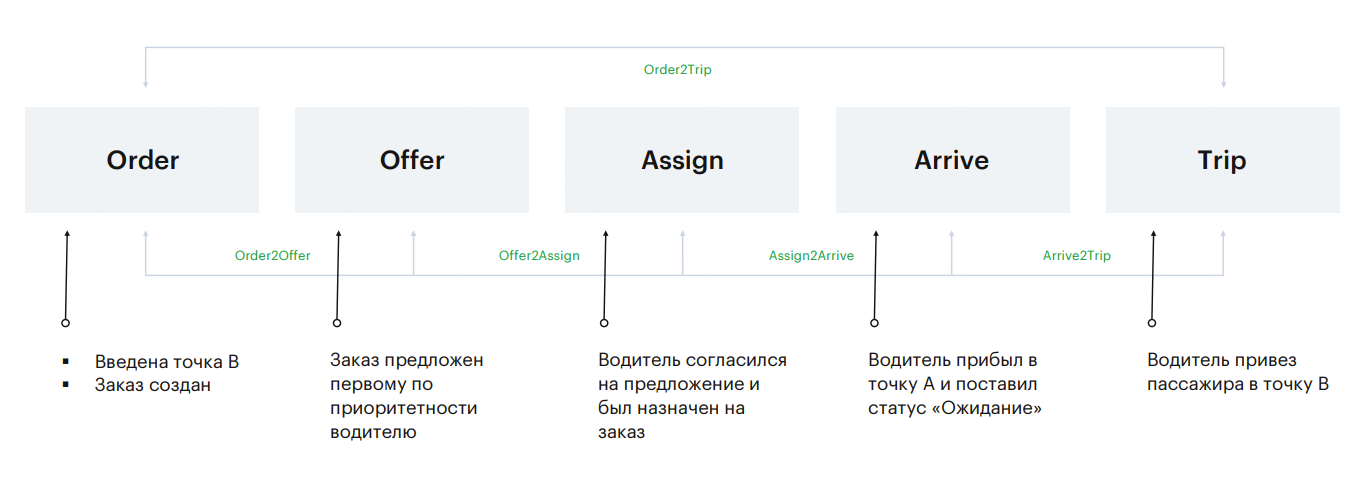

# Описание данных

 - *id_order* - уникальный идентификатор заказа;
 - *test_group* - флаг, относящий заказ к контрольной или тестовой группе;
 - *time_order* - Дата + время создания заказа;
 - *time_offer* - Дата + время первого предложения заказа водителю;
 - *time_assign* - Дата + время согласия и назначения водителя на заказ;
 - *time_arrive* - Дата + время прибытия водителя в точку "А";
 - *trip_time* - Дата + время успешного окончания поездки в точке "В";

In [2]:
df = pd.read_csv('taxi_order_list.csv', sep='\t')

In [3]:
df.head()

,id_order,test_group,time_order,time_offer,time_assign,time_arrive,trip_time
0,10001.0,0.0,04.3.2024 0:00:01,04.3.2024 0:00:42,04.3.2024 0:01:13,04.3.2024 0:09:07,04.3.2024 1:27:28
1,10002.0,0.0,04.3.2024 0:00:22,04.3.2024 0:01:00,04.3.2024 0:01:14,04.3.2024 0:08:45,04.3.2024 0:22:22
2,10003.0,1.0,04.3.2024 0:07:08,04.3.2024 0:07:44,NaN,NaN,NaN
3,10004.0,1.0,04.3.2024 0:07:11,04.3.2024 0:08:21,04.3.2024 0:08:46,04.3.2024 0:21:13,04.3.2024 1:23:25
4,10005.0,0.0,04.3.2024 0:11:59,04.3.2024 0:12:50,04.3.2024 0:13:09,04.3.2024 0:21:43,04.3.2024 0:46:45


# Подготовка данных

Приведём все временные отметки к формату дата+время с помощью функции *to_datetime*.

In [4]:
df['time_order']  = pd.to_datetime(df['time_order'], format = '%d.%m.%Y %H:%M:%S')
df['time_offer']  = pd.to_datetime(df['time_offer'], format = '%d.%m.%Y %H:%M:%S')
df['time_assign'] = pd.to_datetime(df['time_assign'], format = '%d.%m.%Y %H:%M:%S')
df['time_arrive'] = pd.to_datetime(df['time_arrive'], format = '%d.%m.%Y %H:%M:%S')
df['trip_time']   = pd.to_datetime(df['trip_time'], format = '%d.%m.%Y %H:%M:%S')

Проверим, верно ли указан период времени данного датасета.

In [5]:
print(min(df['time_order']))
print(max(df['time_order']))

2024-03-04 00:00:01
2024-03-10 23:45:48


Нам необходимо будет работать с конверсиями, поэтому для упрощения расчётов введём поля-флаги, принимающие значения 1 или 0 в зависимости от наличия того или иного события в рамках данного заказа.

In [6]:
df['flag_offer'] = np.where(~df['time_offer'].isnull(),1,0)
df['flag_assign'] = np.where(~df['time_assign'].isnull(),1,0)
df['flag_arrive'] = np.where(~df['time_arrive'].isnull(),1,0)
df['flag_trip'] = np.where(~df['trip_time'].isnull(),1,0)

Добавим поля, показывающие количество секунд, которые проходят между соседними событиями.

In [7]:
df['len_offer']  = (df['time_offer']  - df['time_order']).dt.seconds
df['len_assign'] = (df['time_assign'] - df['time_offer']).dt.seconds
df['len_arrive'] = (df['time_arrive'] - df['time_assign']).dt.seconds
df['len_trip']   = (df['trip_time']   - df['time_arrive']).dt.seconds

In [8]:
df.head(3)

,id_order,test_group,time_order,time_offer,time_assign,time_arrive,trip_time,flag_offer,flag_assign,flag_arrive,flag_trip,len_offer,len_assign,len_arrive,len_trip
0,10001.0,0.0,2024-03-04 00:00:01,2024-03-04 00:00:42,2024-03-04 00:01:13,2024-03-04 00:09:07,2024-03-04 01:27:28,1,1,1,1,41.0,31.0,474.0,4701.0
1,10002.0,0.0,2024-03-04 00:00:22,2024-03-04 00:01:00,2024-03-04 00:01:14,2024-03-04 00:08:45,2024-03-04 00:22:22,1,1,1,1,38.0,14.0,451.0,817.0
2,10003.0,1.0,2024-03-04 00:07:08,2024-03-04 00:07:44,NaT,NaT,NaT,1,0,0,0,36.0,NaN,NaN,NaN


# Задача 1. Сезоные просадки маркетплейса

### Пункт 1. Визуализация динамики

1. Изучи динамику количества заказов и O2T по дням;

2. Изучи динамику количества заказов и O2T по суточным часам;

**Есть ли какие-то закономерности в динамике?**


Для начала создадим поля, которые будут показывать суточный час создания заказа, а также дату заказа, очищенную от времени.

In [9]:
df['order_hour'] = df['time_order'].dt.hour
df['order_day']  = df['time_order'].dt.to_period('D').dt.to_timestamp()

In [10]:
df.head(3)

,id_order,test_group,time_order,time_offer,time_assign,time_arrive,trip_time,flag_offer,flag_assign,flag_arrive,flag_trip,len_offer,len_assign,len_arrive,len_trip,order_hour,order_day
0,10001.0,0.0,2024-03-04 00:00:01,2024-03-04 00:00:42,2024-03-04 00:01:13,2024-03-04 00:09:07,2024-03-04 01:27:28,1,1,1,1,41.0,31.0,474.0,4701.0,0.0,2024-03-04
1,10002.0,0.0,2024-03-04 00:00:22,2024-03-04 00:01:00,2024-03-04 00:01:14,2024-03-04 00:08:45,2024-03-04 00:22:22,1,1,1,1,38.0,14.0,451.0,817.0,0.0,2024-03-04
2,10003.0,1.0,2024-03-04 00:07:08,2024-03-04 00:07:44,NaT,NaT,NaT,1,0,0,0,36.0,NaN,NaN,NaN,0.0,2024-03-04


Построим группировку: для каждого суточного часа посчитаем количество всех событий, а также все конверсии.

In [11]:
df_gr_h = df.groupby(['order_hour']).agg( cnt_order = ('id_order','count')
                                        , cnt_offer = ('time_offer','count')
                                        , cnt_assign = ('time_assign','count')
                                        , cnt_arrive = ('time_arrive','count')
                                        , cnt_trip = ('trip_time','count')
                                        , avg_len_offer = ('len_offer','mean')
                                        , avg_len_arr = ('len_arrive','mean')
                                        ).reset_index()

df_gr_h['Order2Trip']    = df_gr_h['cnt_trip']   / df_gr_h['cnt_order']
df_gr_h['Order2Offer']   = df_gr_h['cnt_offer']  / df_gr_h['cnt_order']
df_gr_h['Offer2Assign']  = df_gr_h['cnt_assign'] / df_gr_h['cnt_offer']
df_gr_h['Assign2Arrive'] = df_gr_h['cnt_arrive'] / df_gr_h['cnt_assign']
df_gr_h['Arrive2Trip']   = df_gr_h['cnt_trip']   / df_gr_h['cnt_arrive']

df_gr_h.head(3)

,order_hour,cnt_order,cnt_offer,cnt_assign,cnt_arrive,cnt_trip,avg_len_offer,avg_len_arr,Order2Trip,Order2Offer,Offer2Assign,Assign2Arrive,Arrive2Trip
0,0.0,54,52,48,38,38,61.038462,407.631579,0.703704,0.962963,0.923077,0.791667,1.000000
1,1.0,259,233,211,174,168,58.326180,467.097701,0.648649,0.899614,0.905579,0.824645,0.965517
2,2.0,191,172,150,127,123,59.831395,449.842520,0.643979,0.900524,0.872093,0.846667,0.968504


Построим группировку: для каждого дня посчитаем количество всех событий, а также все конверсии.

In [12]:
df_gr_d = df.groupby(['order_day']).agg(  cnt_order = ('id_order','count')
                                        , cnt_offer = ('time_offer','count')
                                        , cnt_assign = ('time_assign','count')
                                        , cnt_arrive = ('time_arrive','count')
                                        , cnt_trip = ('trip_time','count')
                                        , avg_len_offer = ('len_offer','mean')
                                        , avg_len_arr = ('len_arrive','mean')
                                        ).reset_index()

df_gr_d['Order2Trip']    = df_gr_d['cnt_trip']   / df_gr_d['cnt_order']
df_gr_d['Order2Offer']   = df_gr_d['cnt_offer']  / df_gr_d['cnt_order']
df_gr_d['Offer2Assign']  = df_gr_d['cnt_assign'] / df_gr_d['cnt_offer']
df_gr_d['Assign2Arrive'] = df_gr_d['cnt_arrive'] / df_gr_d['cnt_assign']
df_gr_d['Arrive2Trip']   = df_gr_d['cnt_trip']   / df_gr_d['cnt_arrive']

df_gr_d.head(3)

,order_day,cnt_order,cnt_offer,cnt_assign,cnt_arrive,cnt_trip,avg_len_offer,avg_len_arr,Order2Trip,Order2Offer,Offer2Assign,Assign2Arrive,Arrive2Trip
0,2024-03-04,1102,964,874,711,679,62.562241,470.538678,0.616152,0.874773,0.906639,0.813501,0.954993
1,2024-03-05,1138,1014,899,715,685,62.624260,459.746853,0.601933,0.891037,0.886588,0.795328,0.958042
2,2024-03-06,1187,1047,944,770,729,63.725883,466.701299,0.614153,0.882056,0.901624,0.815678,0.946753


#### Динамика по дням

Построим график по дням (можно было бы взять дни недели, но наш датасет ограничивается одной неделей, поэтому возьмём просто даты):

 - По левой оси конверсия Order2Trip
 - По правой оси количество заказов

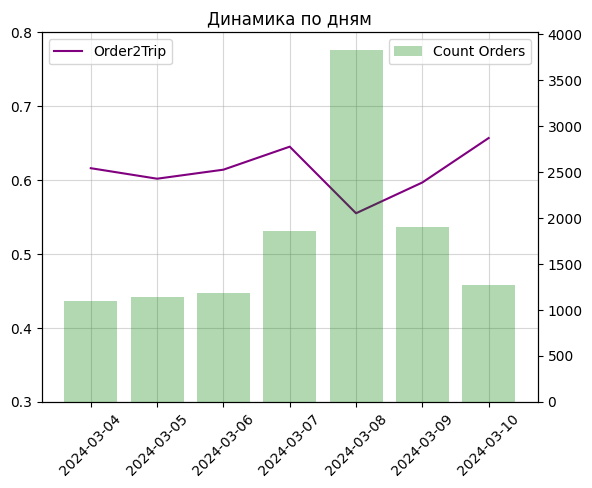

In [13]:
fig, ax = plt.subplots()
ax.plot(df_gr_d['order_day'], df_gr_d['Order2Trip'], color = 'purple', label = 'Order2Trip')
plt.xticks(rotation = 45)
ax2 = ax.twinx()
ax2.bar(df_gr_d['order_day'], df_gr_d['cnt_order'], color = 'green', alpha = .3, label = 'Count Orders')
ax.legend(loc = 'upper left')
ax2.legend()
ax.set_ylim([0.3,0.8])
plt.title('Динамика по дням')
ax.grid(alpha=.5)
plt.show()

**Вывод**

Видим, что в праздничный день 8 марта было значительно больше заказов, чем в любой другой день.


А почему конверсия падает?

#### Динамика по часам

Построим график по суточным часам (то есть всего 24 точки на оси X):

 - По левой оси конверсия Order2Trip
 - По правой оси количество заказов

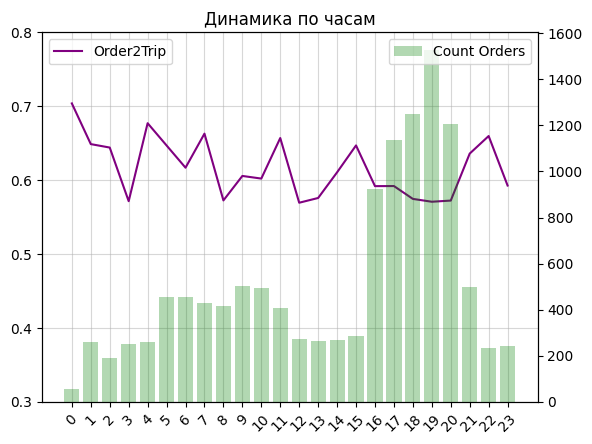

In [14]:
fig, ax = plt.subplots()
ax.plot(df_gr_h['order_hour'], df_gr_h['Order2Trip'], color = 'purple', label = 'Order2Trip')
plt.xticks(rotation = 45)
ax2 = ax.twinx()
ax2.bar(df_gr_h['order_hour'], df_gr_h['cnt_order'], color = 'green', alpha = .3, label = 'Count Orders')
ax.legend(loc = 'upper left')
ax2.legend(loc = 'upper right')
plt.title('Динамика по часам')
plt.xticks(df_gr_h['order_hour'])
ax.set_ylim([0.3,0.8])
ax.grid(alpha=.5)
plt.show()

**Вывод**:

 1. Существует два интервала "час пик": *утренний* (5-10) и *вечерний* (16-21);

 2. Вечерний интервал отличается от среднего сильнее, чем утренний;

### Пункт 2. Статистическая значимость сезонных просадок


#### Часы пик

Правда ли, что были значимые проблемы с агрегатором в часы пик?

  

  1. Правда ли, что на буднях в часы пик конверсия O2T ниже, чем в  остальные часы?

  2. Правда ли, что все звенья конверсии O2T ниже, чем в  остальные часы?

  3. Правда ли, что на буднях в часы пик среднее время поиска водителя выше чем в остальные часы?

  4. Правда ли, что на буднях в часы пик среднее время подачи автомобиля выше чем в остальные часы?



**При ответе на данные вопросы необходимо подтвердить расчеты  статистическими критериями**.

Создадим переменную, которая принимает значение $1$ для часов пик (вместе утренних и вечерних) и значение $0$ для "обычных" часов.

In [15]:
df['is_rush_hour'] = np.where(df['order_hour'].isin([7,8,9,10,17,18,19,20]),1,0)

df.head(3)

,id_order,test_group,time_order,time_offer,time_assign,time_arrive,trip_time,flag_offer,flag_assign,flag_arrive,flag_trip,len_offer,len_assign,len_arrive,len_trip,order_hour,order_day,is_rush_hour
0,10001.0,0.0,2024-03-04 00:00:01,2024-03-04 00:00:42,2024-03-04 00:01:13,2024-03-04 00:09:07,2024-03-04 01:27:28,1,1,1,1,41.0,31.0,474.0,4701.0,0.0,2024-03-04,0
1,10002.0,0.0,2024-03-04 00:00:22,2024-03-04 00:01:00,2024-03-04 00:01:14,2024-03-04 00:08:45,2024-03-04 00:22:22,1,1,1,1,38.0,14.0,451.0,817.0,0.0,2024-03-04,0
2,10003.0,1.0,2024-03-04 00:07:08,2024-03-04 00:07:44,NaT,NaT,NaT,1,0,0,0,36.0,NaN,NaN,NaN,0.0,2024-03-04,0


Сначала сравним все заказы из часов пик со всеми обычными заказами

In [16]:
df_gr_rush = df.groupby('is_rush_hour').agg( cnt_order = ('id_order','count')
                                            , cnt_offer = ('time_offer','count')
                                            , cnt_assign = ('time_assign','count')
                                            , cnt_arrive = ('time_arrive','count')
                                            , cnt_trip = ('trip_time','count')
                                            , avg_len_offer = ('len_offer','mean')
                                            , avg_len_arr = ('len_arrive','mean')
                                            ).reset_index()

df_gr_rush['Order2Trip']    = df_gr_rush['cnt_trip']   / df_gr_rush['cnt_order']
df_gr_rush['Order2Offer']   = df_gr_rush['cnt_offer']  / df_gr_rush['cnt_order']
df_gr_rush['Offer2Assign']  = df_gr_rush['cnt_assign'] / df_gr_rush['cnt_offer']
df_gr_rush['Assign2Arrive'] = df_gr_rush['cnt_arrive'] / df_gr_rush['cnt_assign']
df_gr_rush['Arrive2Trip']   = df_gr_rush['cnt_trip']   / df_gr_rush['cnt_arrive']

df_gr_rush

,is_rush_hour,cnt_order,cnt_offer,cnt_assign,cnt_arrive,cnt_trip,avg_len_offer,avg_len_arr,Order2Trip,Order2Offer,Offer2Assign,Assign2Arrive,Arrive2Trip
0,0,5323,4741,4281,3459,3309,61.564860,461.032090,0.621642,0.890663,0.902974,0.807989,0.956635
1,1,6958,6040,5343,4265,4075,74.143212,487.093552,0.585657,0.868066,0.884603,0.798241,0.955451


**Вывод:**

 1. Общая конверсия O2T в часы пик падает
 2. Количество заказов в часы пик возрастает
 3. Просадки происходят в первую очередь из-за просадки *Order2Offer*, а во вторую - из-за просадки *Offer2Assign*.

 **Перейдём к проверке стат.значимости**

 Везде будет использовать функцию *ttest_ind* со значением параметра *equal_var* по умолчанию.

**Гипотеза 1. Конверсия Order2Trip**

*Базовая конверсия из 5 в 1. Будем рассчитывать для всех наблюдений*.

$H_0: O2T_{rush}=O2T_{reg}$

$H_1: O2T_{rush} \neq O2T_{reg}$


In [17]:
print("Тест на конверсию O2T")
print()
s, p = ttest_ind(df[df['is_rush_hour']==1]['flag_trip'], df[df['is_rush_hour']==0]['flag_trip'])
print("Среднее в час пик = ", df[df['is_rush_hour']==1]['flag_trip'].mean())
print("Среднее в обычное время = ", df[df['is_rush_hour']==0]['flag_trip'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию O2T

Среднее в час пик =  0.5856567979304398
Среднее в обычное время =  0.6215251690458302
Значение стат.критерия =  -4.0253456193326285
p_value =  5.723328244072226e-05


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия O2T в часы пик меньше, чем в обычные часы.

**Гипотеза 2. Конверсия Order2Offer**

*Цепная конверсия из 2 в 1*

$H_0: O2Off_{rush}=O2Off_{reg}$

$H_1: O2Off_{rush} \neq O2Off_{reg}$



In [18]:
s, p = ttest_ind(df[df['is_rush_hour']==1]['flag_offer'], df[df['is_rush_hour']==0]['flag_offer'])
print("Среднее в час пик = ", df[df['is_rush_hour']==1]['flag_offer'].mean())
print("Среднее в обычное время = ", df[df['is_rush_hour']==0]['flag_offer'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Среднее в час пик =  0.8680655360735844
Среднее в обычное время =  0.890495867768595
Значение стат.критерия =  -3.7629330104048186
p_value =  0.00016871355374467657


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия Order2Offer в часы пик меньше, чем в обычные часы.

**Гипотеза 3. Конверсия Offer2Assign**

*Цепная конверсия из 3 в 2. Будем использовать только те заказы, в которых есть найденный водитель, иначе получим Order2Offer*.

$H_0: Off2As_{rush}=Off2As_{reg}$

$H_1: Off2As_{rush} \neq Off2As_{reg}$

In [19]:
s, p = ttest_ind(df[(df['is_rush_hour']==1) & (df['flag_offer']==1)]['flag_assign']
                 , df[(df['is_rush_hour']==0) & (df['flag_offer']==1)]['flag_assign'])

print("Среднее в час пик = ", df[(df['is_rush_hour']==1) & (df['flag_offer']==1)]['flag_assign'].mean())
print("Среднее в обычное время = ", df[(df['is_rush_hour']==0) & (df['flag_offer']==1)]['flag_assign'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Среднее в час пик =  0.8846026490066226
Среднее в обычное время =  0.9029740561063067
Значение стат.критерия =  -3.0600545998390167
p_value =  0.0022184051317264753


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия Offer2Assign в часы пик меньше, чем в обычные часы.

**Гипотеза 4. Конверсия Assign2Arrive**

*Цепная конверсия из 4 в 3. Будем использовать только те заказы, в которых есть назначенный водитель, иначе получим Order2Arrive*.

$H_0: As2Ar_{rush}=As2Ar_{reg}$

$H_1: As2Ar_{rush} \neq As2Ar_{reg}$

In [20]:
print("Тест на конверсию Assign2Arrive")
print()
s, p = ttest_ind(df[(df['is_rush_hour']==1) & (df['flag_assign']==1)]['flag_arrive']
                 , df[(df['is_rush_hour']==0) & (df['flag_assign']==1)]['flag_arrive'])

print("Среднее в час пик = ", df[(df['is_rush_hour']==1) & (df['flag_assign']==1)]['flag_arrive'].mean())
print("Среднее в обычное время = ", df[(df['is_rush_hour']==0) & (df['flag_assign']==1)]['flag_arrive'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Assign2Arrive

Среднее в час пик =  0.7982406887516377
Среднее в обычное время =  0.8079887876664331
Значение стат.критерия =  -1.1938562433630158
p_value =  0.23256363841164956


**Вывод**:

p_value больше, чем $\alpha$, поэтому **нельзя** сделать вывод о наличии статистически значимой разницы.

**Гипотеза 5. Конверсия Arrive2Trip**

$H_0: Ar2T_{rush}=Ar2T_{reg}$

$H_1: Ar2T_{rush} \neq Ar2T_{reg}$

*Цепная конверсия из 5 в 4. Будем использовать только те заказы, в которых есть назначенный водитель, иначе получим Order2Trip*.


In [21]:
print("Тест на конверсию Arrive2Trip")
print()
s, p = ttest_ind(df[(df['is_rush_hour']==1) & (df['flag_arrive']==1)]['flag_trip']
                 , df[(df['is_rush_hour']==0) & (df['flag_arrive']==1)]['flag_trip'])

print("Среднее в час пик = ", df[(df['is_rush_hour']==1) & (df['flag_arrive']==1)]['flag_trip'].mean())
print("Среднее в обычное время = ", df[(df['is_rush_hour']==0) & (df['flag_arrive']==1)]['flag_trip'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Arrive2Trip

Среднее в час пик =  0.9554513481828839
Среднее в обычное время =  0.9566348655680833
Значение стат.критерия =  -0.2521104363346805
p_value =  0.800962412988413


**Вывод**:

p_value больше, чем $\alpha$, поэтому **нельзя** сделать вывод о наличии статистически значимой разницы.

**Гипотеза 6. Время поиска водителя**

$H_0: DST_{rush}=DST_{reg}$

$H_1: DST_{rush} \neq DST_{reg}$

Будем использовать только те заказы, в которых есть найденный водитель, иначе время поиска водителя не имеет смысла.

In [22]:
print("Тест на время поиска водителя")
print()
s, p = ttest_ind(df[(df['is_rush_hour']==1) & (~df['len_offer'].isnull())]['len_offer']
                 , df[(df['is_rush_hour']==0) & (~df['len_offer'].isnull())]['len_offer'])

print("Среднее в час пик = ", df[(df['is_rush_hour']==1) & (~df['len_offer'].isnull())]['len_offer'].mean())
print("Среднее в обычное время = ", df[(df['is_rush_hour']==0) & (~df['len_offer'].isnull())]['len_offer'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на время поиска водителя

Среднее в час пик =  74.14321192052981
Среднее в обычное время =  61.56485973423328
Значение стат.критерия =  27.62147459777334
p_value =  2.5339227515770905e-162


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: время поиска водителя в часы пик больше, чем в обычные часы.

**Гипотеза 7. Время подачи автомобиля**

*Будем использовать только те заказы, в которых есть прибытие в точку А, иначе время подачи автомобиля не имеет смысла.*

$H_0: ETA_{rush}=ETA_{reg}$

$H_1: ETA_{rush} \neq ETA_{reg}$



In [23]:
print("Тест на время прибытия водителя (ETA)")
print()
s, p = ttest_ind(df[(df['is_rush_hour']==1) & (~df['len_arrive'].isnull())]['len_arrive']
                 , df[(df['is_rush_hour']==0) & (~df['len_arrive'].isnull())]['len_arrive'])

print("Среднее в час пик = ", df[(df['is_rush_hour']==1) & (~df['len_arrive'].isnull())]['len_arrive'].mean())
print("Среднее в обычное время = ", df[(df['is_rush_hour']==0) & (~df['len_arrive'].isnull())]['len_arrive'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на время прибытия водителя (ETA)

Среднее в час пик =  487.09355216881596
Среднее в обычное время =  461.0320901994796
Значение стат.критерия =  5.4575914292527425
p_value =  4.976076176254069e-08


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: время подачи автомобиля в часы пик больше, чем в обычные часы.

#### 8 марта

 - Правда ли, что конверсия O2T 8 марта была ниже, чем в среднем за остальные дни (как и промежуточные конверсии)?

  - Правда ли, что среднее время поиска водителя было выше 8 марта, чем в остальные дни?

  - Правда ли, что среднее время подачи автомобиля было выше 8 марта, чем в остальные дни?

Создадим поле-флаг, чтобы обозначить единицами заказы, относящиеся к 8 марта.

In [24]:
df['is_8march'] = np.where(df['order_day'].dt.day==8,1,0)

In [25]:
df_gr_8 = df.groupby('is_8march').agg( cnt_order = ('id_order','count')
                                            , cnt_offer = ('time_offer','count')
                                            , cnt_assign = ('time_assign','count')
                                            , cnt_arrive = ('time_arrive','count')
                                            , cnt_trip = ('trip_time','count')
                                            , avg_len_offer = ('len_offer','mean')
                                            , avg_len_arr = ('len_arrive','mean')
                                          ).reset_index()

df_gr_8['Order2Trip']    = df_gr_8['cnt_trip']   / df_gr_8['cnt_order']
df_gr_8['Order2Offer']   = df_gr_8['cnt_offer']  / df_gr_8['cnt_order']
df_gr_8['Offer2Assign']  = df_gr_8['cnt_assign'] / df_gr_8['cnt_offer']
df_gr_8['Assign2Arrive'] = df_gr_8['cnt_arrive'] / df_gr_8['cnt_assign']
df_gr_8['Arrive2Trip']   = df_gr_8['cnt_trip']   / df_gr_8['cnt_arrive']

df_gr_8

,is_8march,cnt_order,cnt_offer,cnt_assign,cnt_arrive,cnt_trip,avg_len_offer,avg_len_arr,Order2Trip,Order2Offer,Offer2Assign,Assign2Arrive,Arrive2Trip
0,0,8450,7479,6729,5506,5257,62.140126,465.229568,0.622130,0.885089,0.899719,0.818249,0.954777
1,1,3831,3302,2895,2218,2127,83.270139,500.725879,0.555208,0.861916,0.876741,0.766149,0.958972


Видим, что 8 марта:
 - Больше заказов, чем в 1 обычный день
 - Просела конверсия O2T
 - Просели все звенья воронки, кроме Arrive2Trip
 - Выросли время поиска водителя и время подачи автомобиля

Перейдём к расчёту стат.значимости.

In [26]:
print("Тест на конверсию O2T")
print()
s, p = ttest_ind(df[df['is_8march']==1]['flag_trip'], df[df['is_8march']==0]['flag_trip'])
print("Среднее 8 марта = ", df[df['is_8march']==1]['flag_trip'].mean())
print("Среднее в остальные дни = ", df[df['is_8march']==0]['flag_trip'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию O2T

Среднее 8 марта =  0.5552075176194206
Среднее в остальные дни =  0.6220565613536859
Значение стат.критерия =  -7.022951778877622
p_value =  2.2868191897216614e-12


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия O2T 8 марта меньше, чем в остальные дни.

In [27]:
print("Тест на конверсию Order2Offer")
print()
s, p = ttest_ind(df[df['is_8march']==1]['flag_offer'], df[df['is_8march']==0]['flag_offer'])
print("Среднее 8 марта = ", df[df['is_8march']==1]['flag_offer'].mean())
print("Среднее в остальные дни = ", df[df['is_8march']==0]['flag_offer'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Order2Offer

Среднее 8 марта =  0.8619159488384234
Среднее в остальные дни =  0.8849840255591054
Значение стат.критерия =  -3.617696546537784
p_value =  0.00029842938025629245


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия Order2Offer 8 марта меньше, чем в остальные дни.

In [28]:
print("Тест на конверсию Offer2Assign")
print()
s, p = ttest_ind(df[(df['is_8march']==1) & (df['flag_offer']==1)]['flag_assign']
                 , df[(df['is_8march']==0) & (df['flag_offer']==1)]['flag_assign'])

print("Среднее 8 марта = ", df[(df['is_8march']==1) & (df['flag_offer']==1)]['flag_assign'].mean())
print("Среднее в остальные дни = ", df[(df['is_8march']==0) & (df['flag_offer']==1)]['flag_assign'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Offer2Assign

Среднее 8 марта =  0.8767413688673531
Среднее в остальные дни =  0.8997192137986362
Значение стат.критерия =  -3.55482944751035
p_value =  0.000379843854084894


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия Offer2Assign 8 марта меньше, чем в остальные дни.

In [29]:
print("Тест на конверсию Assign2Arrive")
print()
s, p = ttest_ind(df[(df['is_8march']==1) & (df['flag_assign']==1)]['flag_arrive']
                 , df[(df['is_8march']==0) & (df['flag_assign']==1)]['flag_arrive'])

print("Среднее 8 марта = ", df[(df['is_8march']==1) & (df['flag_assign']==1)]['flag_arrive'].mean())
print("Среднее в остальные дни = ", df[(df['is_8march']==0) & (df['flag_assign']==1)]['flag_arrive'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Assign2Arrive

Среднее 8 марта =  0.7661485319516408
Среднее в остальные дни =  0.8182493684054094
Значение стат.критерия =  -5.8987886076082034
p_value =  3.785282978766433e-09


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: конверсия Assign2Arrive 8 марта меньше, чем в остальные дни.

In [30]:
print("Тест на конверсию Arrive2Trip")
print()
s, p = ttest_ind(df[(df['is_8march']==1) & (df['flag_arrive']==1)]['flag_trip']
                 , df[(df['is_8march']==0) & (df['flag_arrive']==1)]['flag_trip'])

print("Среднее 8 марта = ", df[(df['is_8march']==1) & (df['flag_arrive']==1)]['flag_trip'].mean())
print("Среднее в остальные дни = ", df[(df['is_8march']==0) & (df['flag_arrive']==1)]['flag_trip'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Arrive2Trip

Среднее 8 марта =  0.9589720468890893
Среднее в остальные дни =  0.9547766073374501
Значение стат.критерия =  0.8131572376987557
p_value =  0.4161529834356513


**Вывод**:

p_value больше, чем $\alpha$, поэтому **нельзя** сделать вывод о наличии статистически значимой разницы.

In [31]:
print("Тест на время поиска водителя")
print()
s, p = ttest_ind(df[(df['is_8march']==1) & (~df['len_offer'].isnull())]['len_offer']
                 , df[(df['is_8march']==0) & (~df['len_offer'].isnull())]['len_offer'])

print("Среднее 8 марта = ", df[(df['is_8march']==1) & (~df['len_offer'].isnull())]['len_offer'].mean())
print("Среднее в остальные дни = ", df[(df['is_8march']==0) & (~df['len_offer'].isnull())]['len_offer'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на время поиска водителя

Среднее 8 марта =  83.27013930950939
Среднее в остальные дни =  62.14012568525204
Значение стат.критерия =  45.45852632463483
p_value =  0.0


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: время поиска водителя 8 марта больше, чем в остальные дни.

In [32]:
print("Тест на время прибытия водителя (ETA)")
print()
s, p = ttest_ind(df[(df['is_8march']==1) & (~df['len_arrive'].isnull())]['len_arrive']
                 , df[(df['is_8march']==0) & (~df['len_arrive'].isnull())]['len_arrive'])

print("Среднее 8 марта = ", df[(df['is_8march']==1) & (~df['len_arrive'].isnull())]['len_arrive'].mean())
print("Среднее в остальные дни = ", df[(df['is_8march']==0) & (~df['len_arrive'].isnull())]['len_arrive'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на время прибытия водителя (ETA)

Среднее 8 марта =  500.7258791704238
Среднее в остальные дни =  465.229567744279
Значение стат.критерия =  6.770155991977973
p_value =  1.380649884819453e-11


**Вывод**:

p_value меньше, чем $\alpha$, поэтому **можно** сделать вывод о наличии статистически значимой разницы: время подачи автомобиля 8 марта больше, чем в остальные дни.

# Задача 2. Отложенные заказы

1. Изучи отложенные заказы (заказ к конкретному времени). В нашей витрине нет информации об отложенных заказах. Как бы ты выделил их на основании имеющейся информации?

2. Можно ли сделать вывод, что отложенные заказы отличаются от срочных с точки зрения звеньев конверсии?

3. Опиши алгоритм приложения по работе с отложенными заказами с точки зрения водителя и клиента.

Мы не знаем конкретный процесс "под капотом" агрегатора такси, поэтому мы не знаем, на каком конкретно звене воронки скажется отложенный заказ.

Выведем топ-3 самые длинные отметки для каждого из столбцов времени между ивентами.

In [33]:
df.sort_values('len_offer', ascending = False)['len_offer'].head(3)

,len_offer
7234,129.0
9343,128.0
8415,127.0


In [34]:
df.sort_values('len_assign', ascending = False)['len_assign'].head(3)

,len_assign
4875,82845.0
6382,82840.0
7743,82839.0


In [35]:
df.sort_values('len_arrive', ascending = False)['len_arrive'].head(3)

,len_arrive
9353,963.0
7770,960.0
12034,958.0


**Вывод**

Статус отложенного заказа сказывается на времени между Offer и Assign.

Пример процесса под капотом:

 - Клиент делает заказ в 17:40 01.02.2026. Заказ на 12:00 03.02.2026
 - На заказ сразу же ищется водитель, который соглашается, например, в 17:43 01.02.2026
 - Однако событие назначения не происходит пока что, оно произойдёт только ближе ко времени непосредственной поездки.

*В реальности могут быть разные варианты данного процесса.*

Теперь необходимо отрезать отложенные заказы.

Так как у нас нет явного флага "отложенности", воспользуемся обрезанием выбросов по полю *len_assign*.

Пройдёмся по топ-квантилям данного поля и посмотрим, есть ли резкие скачки между квантилями.

In [36]:
for i in range(1,20):
  print(round(.8+i*.01,2), "=", round(np.quantile(df[~df['len_assign'].isnull()]['len_assign'], .8+i*.01),0))

0.81 = 39.0
0.82 = 40.0
0.83 = 40.0
0.84 = 40.0
0.85 = 40.0
0.86 = 41.0
0.87 = 41.0
0.88 = 43.0
0.89 = 43.0
0.9 = 44.0
0.91 = 3627.0
0.92 = 10838.0
0.93 = 21632.0
0.94 = 32416.0
0.95 = 39635.0
0.96 = 50420.0
0.97 = 57632.0
0.98 = 68423.0
0.99 = 75633.0


Видим резкий скачок между $90$ и $91$ перцентилями.

Зададим *пороговое значение* где-то между данными значениями. Например, возьмём $100$ секунд.

Создадим флаг "отложенности" в таблице и построим сводную, чтобы оценить отличие отложенных заказов от обычных с точки зрения метрик.

In [37]:
df['flag_delay'] = np.where(df['len_assign'] > 100, 1, 0)

dfc      = df[df['flag_delay']==0]
df_delay = df[df['flag_delay']==1]

In [38]:
df_delay = df.groupby('flag_delay').agg(cnt_order     = ('time_order','count')
                                        , cnt_offer     = ('time_offer','count')
                                        , cnt_assign    = ('time_assign','count')
                                        , cnt_arrive    = ('time_arrive','count')
                                        , cnt_trip      = ('trip_time','count')
                                        , avg_len_offer = ('len_offer','mean')
                                        , avg_len_arr   = ('len_arrive','mean')
                                        ).reset_index()
df_delay['Order2Trip']    = df_delay['cnt_trip']   / df_delay['cnt_order']
df_delay['Order2Offer']   = df_delay['cnt_offer']  / df_delay['cnt_order']
df_delay['Offer2Assign']  = df_delay['cnt_assign'] / df_delay['cnt_offer']
df_delay['Assign2Arrive'] = df_delay['cnt_arrive'] / df_delay['cnt_assign']
df_delay['Arrive2Trip']   = df_delay['cnt_trip']   / df_delay['cnt_arrive']

df_delay

,flag_delay,cnt_order,cnt_offer,cnt_assign,cnt_arrive,cnt_trip,avg_len_offer,avg_len_arr,Order2Trip,Order2Offer,Offer2Assign,Assign2Arrive,Arrive2Trip
0,0,11394,9894,8737,7106,6851,68.579442,470.103856,0.601281,0.868352,0.88306,0.813323,0.964115
1,1,887,887,887,618,533,68.972943,536.579288,0.600902,1.000000,1.00000,0.696731,0.862460


In [39]:
print("Тест на конверсию Order2Trip")
print()
s, p = ttest_ind(df[df['flag_delay']==1]['flag_trip'], df[df['flag_delay']==0]['flag_trip'])
print("Среднее по отложенным = ", df[df['flag_delay']==1]['flag_trip'].mean())
print("Среднее по срочным = ", df[df['flag_delay']==0]['flag_trip'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Order2Trip

Среднее по отложенным =  0.6009019165727171
Среднее по срочным =  0.6012286090390522
Значение стат.критерия =  -0.019138242346539512
p_value =  0.98473113495652


In [40]:
print("Тест на конверсию Order2Assign")
print()
s, p = ttest_ind(df[df['flag_delay']==1]['flag_assign'], df[df['flag_delay']==0]['flag_assign'])
print("Среднее по отложенным = ", df[df['flag_delay']==1]['flag_assign'].mean())
print("Среднее по срочным = ", df[df['flag_delay']==0]['flag_assign'].mean())
print("Значение стат.критерия = ", s)
print("p_value = ", p)

Тест на конверсию Order2Assign

Среднее по отложенным =  1.0
Среднее по срочным =  0.7667397981570865
Значение стат.критерия =  16.425657664870144
p_value =  5.458210532125096e-60


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


**Вывод**:

Статистически значимого различия между отложенными и срочными заказами в O2А есть, а в O2T нет, однако стоит держать в уме, что они по природе своих звеньев разные.

 - Конверсия Order2Offer на отложенных заказах составляет $100\%$, так как мы всегда найдём, кому предложить данный заказ, ввиду отсутствия срочности.

 - Конверсия Offer2Assign на отложенных заказах составляет $100\%$, так как мы всегда найдём водителя, который рано или поздно согласится на этот заказ, ввиду отсутствия срочности.

 - Конверсия Assign2Arrive хуже на отложенных заказах, так как водитель соглашается на заказ, который будет нескоро и его планы могут измениться

 - Конверсия Arrive2Trip хуже на отложенных заказах, так как ввиду усложнённой механики выше вероятность фрода. Например, водитель с помощью "мок-координат" делает вид, что он в точке А, а на самом деле сам туда не приехал и таким образом вынуждает клиента отменить заказ.

Разница во всех конверсиях достаточно большая, чтобы на данном количестве наблюдений не проводить тест на статистическую значимость (опираясь на результаты прошлых проверок).

# Задача 3. A/B тест на увеличение радиуса поиска

***Справка***
1. **Таргет-метрика** - метрика, которую мы планируем в результате эксперимента улучшить (в случае конверсии - повысить, в случае средних издержек - снизить);

2. **Гард-метрика** - метрика, которая, как мы опасаемся, в результате эксперимента может ухудшиться (a.k.a GuardRail Metric);

3. Результирующее сочетание изменений таргет- и гард-метрик позволяют вынести вердикт по проведенному эксперименту;

## Описание

В течение этой недели у нас проводился продуктовый эксперимент (A/B Тест), целью которого было **повышение назначаемости водителей**.

Заказов в последнее время больше чем доступных водителей, поэтому хотим протестировать эффективность расширения радиуса.

Для половины заказов при поиске водителя выдавался **расширенный радиус поиска** (5 км вместо 3 км), а другой половине - привычный радиус в 3 км.

Заказы определялись в группы рандомным образом.

Информация о группе содержится в колонке *test_group*.

- 1 - *тестовая* группа (5 км)
- 0 - *контрольная* группа (3 км)

Вам необходимо изучить результаты этого эксперимента и сделать вывод о разумности внедрения данного изменения в Саратове.


**Подсказка**

Обратите внимание на то, как распределяются по группам отложенные заказы. Что вы можете сказать о системе распределения?


## Схема примера

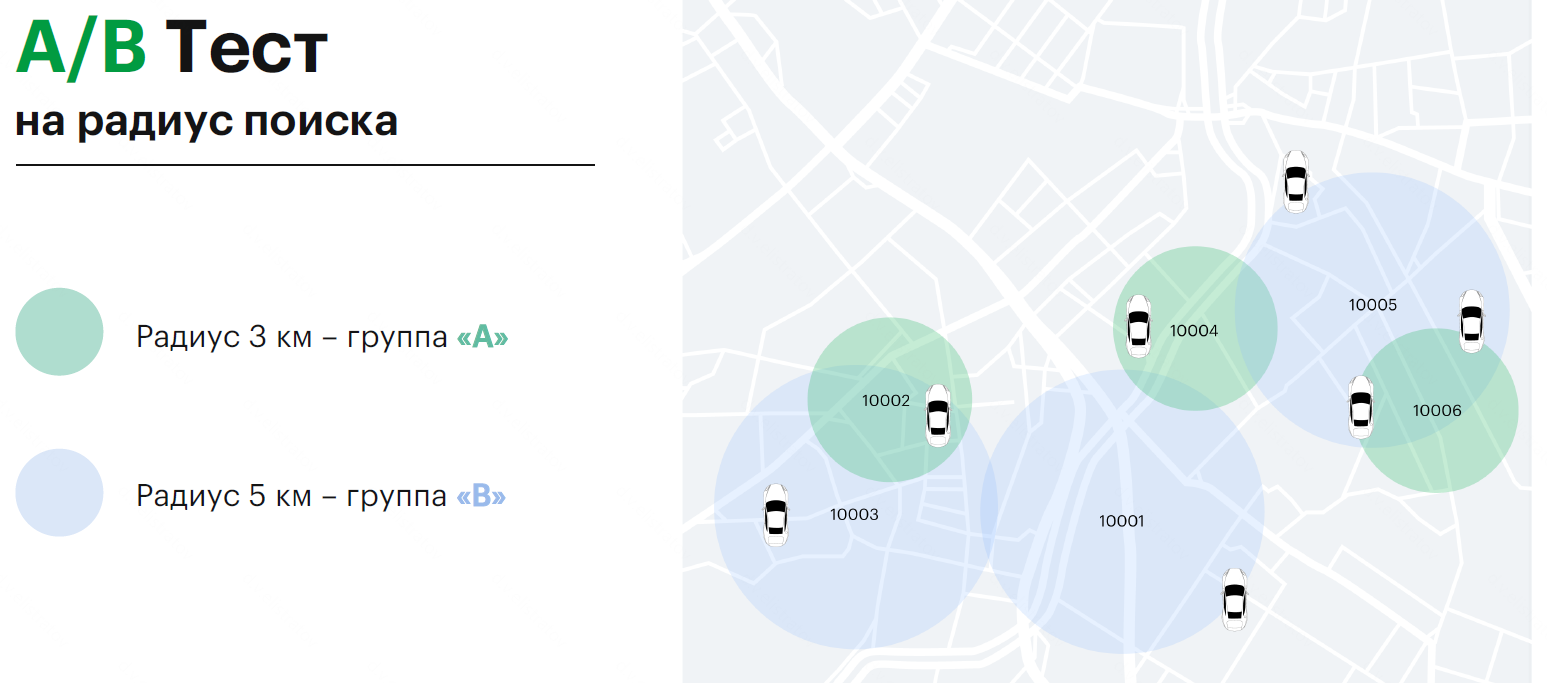

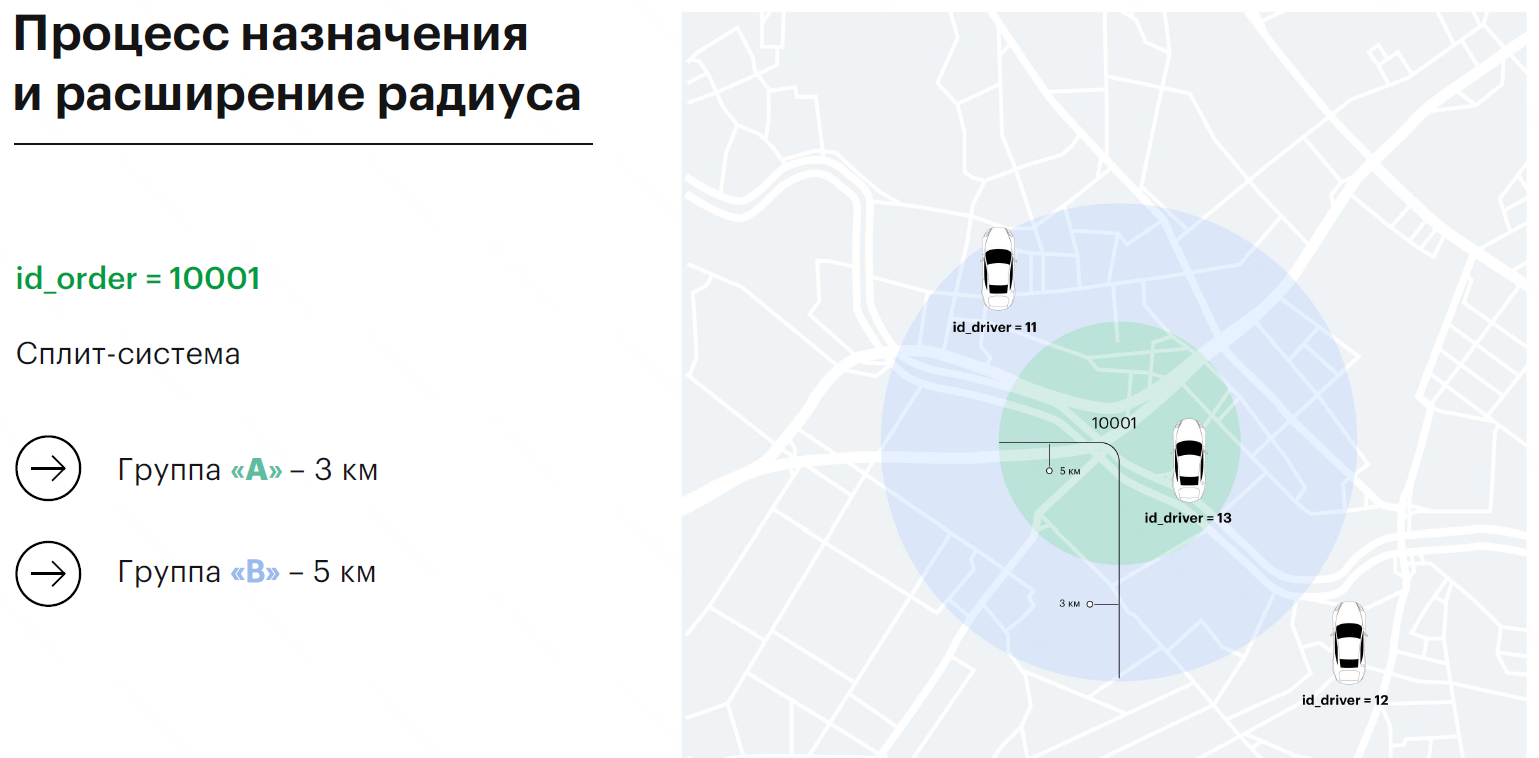

**Если заказ попадёт в группу А, то у заказа будет больше вероятность отвалиться на первом этапе, если не найдётся водителей**.

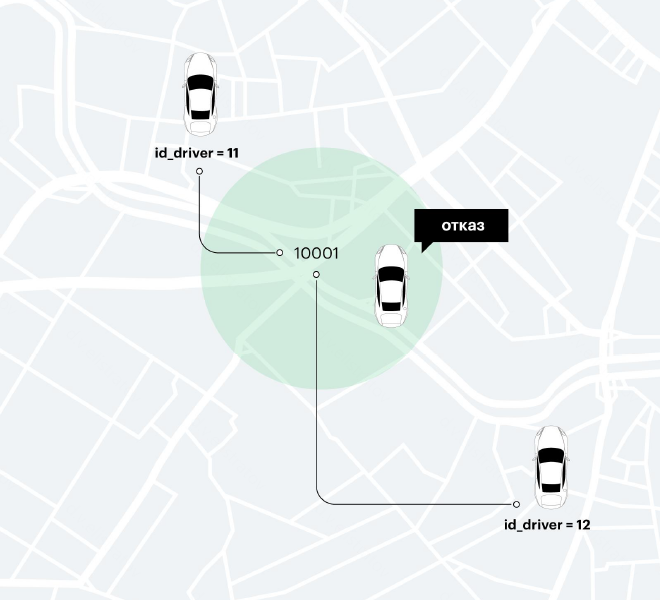

**Если заказ попадёт в группу B, то у заказа будет больше вероятность получить всё же назначенного водителя**.

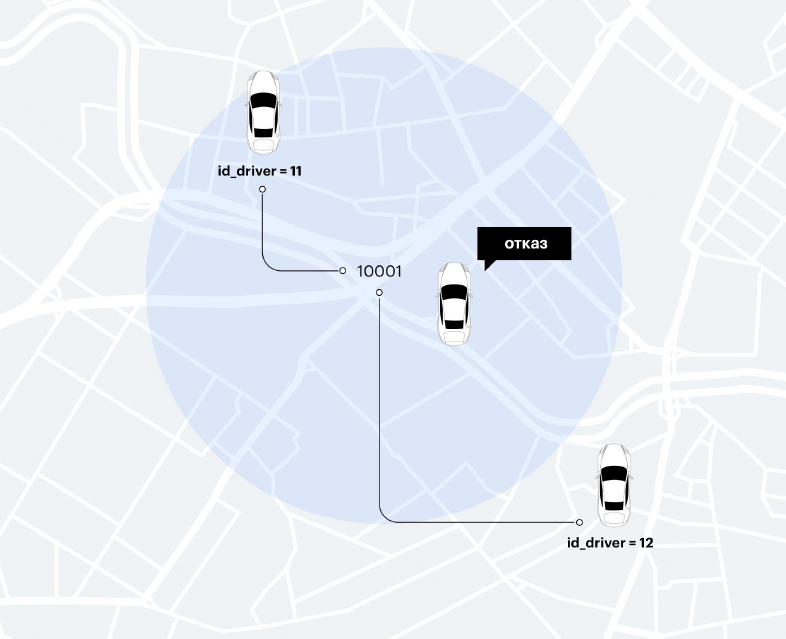

**Вопрос**

Какую следует выбрать *гард-метрику*?

## Сплит-система

Вам необходимо проверить сплит-систему нашего A/B теста.

***Справка***: сплит-система - это алгоритм, который делит единицы наблюдения (в данном случае заказы) на тестовую и контрольную группу в соответствии с заданной пропорцией.

Задача качественной сплит-системы - разделить единицы наблюдения в точности в соответствии с пропорцией.

В нашем случае - это 50 на 50.

С помощью статистического критерия выясните, можно ли доверять нашей сплит-системе.

Определить наличие статистически значимого отличия доли тестовой группы от бенчмарка в $50\%$ можно с помощью одновыборочного Z-критерия.

Рассчитаем его вручную.

In [41]:
print(df.head(3))
test_sum = df['test_group'].sum()
n = len(df['test_group'])
r = test_sum / n

print(r)

   id_order  test_group          time_order          time_offer  \
0   10001.0         0.0 2024-03-04 00:00:01 2024-03-04 00:00:42   
1   10002.0         0.0 2024-03-04 00:00:22 2024-03-04 00:01:00   
2   10003.0         1.0 2024-03-04 00:07:08 2024-03-04 00:07:44   

          time_assign         time_arrive           trip_time  flag_offer  \
0 2024-03-04 00:01:13 2024-03-04 00:09:07 2024-03-04 01:27:28           1   
1 2024-03-04 00:01:14 2024-03-04 00:08:45 2024-03-04 00:22:22           1   
2                 NaT                 NaT                 NaT           1   

   flag_assign  flag_arrive  flag_trip  len_offer  len_assign  len_arrive  \
0            1            1          1       41.0        31.0       474.0   
1            1            1          1       38.0        14.0       451.0   
2            0            0          0       36.0         NaN         NaN   

   len_trip  order_hour  order_day  is_rush_hour  is_8march  flag_delay  
0    4701.0         0.0 2024-03-04     

$H_0: S=50\%$

$H_1: S \neq 50\%$

In [42]:
z = (r-.5)/(r*(1-r)/n)**.5

print(z)

8.252032174992788


Сравним полученное значение Z с пороговым квантильным значением $1.96$ и увидим, что мы попадаем в критическую зону. То есть доля тестовой группы значимо отличается от бенчмарка в $50\%$.

**Гипотеза**

Какой-то сегмент распределился неверно. проверим отложенные заказы.

In [43]:
df.groupby(['test_group', 'flag_delay']).count()['id_order'].reset_index()

,test_group,flag_delay,id_order
0,0.0,0,5684
1,1.0,0,5710
2,1.0,1,887


Видим, что при дизайне нашего эксперимента была допущена ошибка - все отложенные заказы попали в тестовую группу, что нарушает требование о случайности выбора групп.

Выкинем отложенные заказы и перерассчитаем долю тестовых наблюдений.

In [44]:
test_sum = dfc['test_group'].sum()
n = len(dfc['test_group'])
r = test_sum / n

print(r)
print((r-.5)/(r*(1-r)/n)**.5)

0.5010969723562966
0.23419838134383536


Теперь видим, что нет статистически значимого отличия доли тестовых наблюдений от бенчмарка в $50\%$.

## A/B тест

Сначала подумаем: какие метрики можно назвать *таргетом* и/или *гардом* в этом A/B тесте?

**Ответ**

 1. **Таргет-метрика** - конверсия в нахождение водителя + время поиска водителя;

 2. **North Star метрика** (aka глобальный таргет) - конверсия из заказа в завершённую поездку;

 3. **Гард-метрика** - конверсия из назначения водителя в прибытие в точку А + ETA;

Перейдём к расчётам и не забудем выкинуть все отложенные заказы, так как по своей природе они сильно отличаются от срочных и будут искажать результаты эксперимента.

In [45]:
df_ab_test = df[df['flag_delay']==0].groupby('test_group').agg( cnt_order     = ('time_order','count')
                                                              , cnt_offer     = ('time_offer','count')
                                                              , cnt_assign    = ('time_assign','count')
                                                              , cnt_arrive    = ('time_arrive','count')
                                                              , cnt_trip      = ('trip_time','count')
                                                              , avg_len_offer = ('len_offer','mean')
                                                              , avg_len_arr   = ('len_arrive','mean')
                                                              ).reset_index()
df_ab_test['Order2Trip']    = df_ab_test['cnt_trip']   / df_ab_test['cnt_order']
df_ab_test['Order2Offer']   = df_ab_test['cnt_offer']  / df_ab_test['cnt_order']
df_ab_test['Offer2Assign']  = df_ab_test['cnt_assign'] / df_ab_test['cnt_offer']
df_ab_test['Assign2Arrive'] = df_ab_test['cnt_arrive'] / df_ab_test['cnt_assign']
df_ab_test['Arrive2Trip']   = df_ab_test['cnt_trip']   / df_ab_test['cnt_arrive']
df_ab_test

,test_group,cnt_order,cnt_offer,cnt_assign,cnt_arrive,cnt_trip,avg_len_offer,avg_len_arr,Order2Trip,Order2Offer,Offer2Assign,Assign2Arrive,Arrive2Trip
0,0.0,5684,4846,4285,3689,3562,68.297152,405.217674,0.626671,0.852569,0.884234,0.86091,0.965573
1,1.0,5710,5048,4452,3417,3289,68.850436,540.155107,0.576007,0.884063,0.881933,0.76752,0.962540


**Гипотеза 1. Конверсия Order2Trip**

$H_0: O2T_{test}=O2T_{control}$

$H_0: O2T_{test} \neq O2T_{control}$


In [46]:
print("Сравнение Order2Trip")
s, p = ttest_ind(dfc[dfc['test_group']==1]['flag_trip'], dfc[dfc['test_group']==0]['flag_trip'])
print("Значение стат.критерия = ", s, ", p_value = ", p)
print("Среднее в тестовой группе = ", dfc[dfc['test_group']==1]['flag_trip'].mean())
print("Среднее в контрольной группе = ", dfc[dfc['test_group']==0]['flag_trip'].mean())

Сравнение Order2Trip
Значение стат.критерия =  -5.52944115829522 , p_value =  3.283330090895096e-08
Среднее в тестовой группе =  0.5760070052539404
Среднее в контрольной группе =  0.6266713581984518


**Гипотеза 2. Конверсия Order2Offer**

$H_0: O2Off_{test}=O2Off_{control}$

$H_0: O2Off_{test} \neq O2Off_{control}$


In [47]:
print("Сравнение Order2Offer")
s, p = ttest_ind(dfc[dfc['test_group']==1]['flag_offer'], dfc[dfc['test_group']==0]['flag_offer'])
print("Значение стат.критерия = ", s, ", p_value = ", p)
print("Среднее в тестовой группе = ", dfc[dfc['test_group']==1]['flag_offer'].mean())
print("Среднее в контрольной группе = ", dfc[dfc['test_group']==0]['flag_offer'].mean())
print()

Сравнение Order2Offer
Значение стат.критерия =  4.976440767031527 , p_value =  6.571058464896865e-07
Среднее в тестовой группе =  0.8840630472854641
Среднее в контрольной группе =  0.8525686136523575



**Гипотеза 3. Конверсия Offer2Assign**

$H_0: Offer2Assign_{test}=Offer2Assign_{control}$

$H_0: Offer2Assign_{test} \neq Offer2Assign_{control}$


In [48]:
print("Сравнение Offer2Assign")
s, p = ttest_ind(dfc[(dfc['test_group']==1) & (dfc['flag_offer']==1)]['flag_assign']
                 , dfc[(dfc['test_group']==0) & (dfc['flag_offer']==1)]['flag_assign'])
print("Значение стат.критерия = ", s, ", p_value = ", p)
print("Среднее в тестовой группе = ", dfc[dfc['test_group']==1]['flag_arrive'].mean())
print("Среднее в контрольной группе = ", dfc[dfc['test_group']==0]['flag_arrive'].mean())
print()

Сравнение Offer2Assign
Значение стат.критерия =  -0.3560093699451252 , p_value =  0.7218411400733358
Среднее в тестовой группе =  0.5984238178633976
Среднее в контрольной группе =  0.6490147783251231



**Гипотеза 4. Конверсия Assign2Arrive**

$H_0: Assign2Arrive_{test}= Assign2Arrive_{control}$

$H_0: Assign2Arrive_{test} \neq Assign2Arrive_{control}$


In [49]:
print("Сравнение Assign2Arrive")
s, p = ttest_ind(  dfc[(dfc['test_group']==1) & (dfc['flag_assign']==1)]['flag_arrive']
                 , dfc[(dfc['test_group']==0) & (dfc['flag_assign']==1)]['flag_arrive'])
print("Значение стат.критерия = ", s, ", p_value = ", p)
print("Среднее в тестовой группе = ", dfc[(dfc['test_group']==1) & (dfc['flag_assign']==1)]['flag_arrive'].mean())
print("Среднее в контрольной группе = ", dfc[(dfc['test_group']==0) & (dfc['flag_assign']==1)]['flag_arrive'].mean())
print()

Сравнение Assign2Arrive
Значение стат.критерия =  -11.2793702594133 , p_value =  2.644276323224398e-29
Среднее в тестовой группе =  0.7675202156334232
Среднее в контрольной группе =  0.8609101516919486



**Теперь посмотрим на временные метрики**.

In [50]:
print("Сравнение Len Offer")
s, p = ttest_ind(  dfc[(dfc['test_group']==1) & (dfc['flag_offer']==1)]['len_offer']
                 , dfc[(dfc['test_group']==0) & (dfc['flag_offer']==1)]['len_offer'])
print("Значение стат.критерия = ", s, ", p_value = ", p)
print("Среднее в тестовой группе = ",dfc[(dfc['test_group']==1) & (dfc['flag_offer']==1)]['len_offer'].mean())
print("Среднее в контрольной группе = ",dfc[(dfc['test_group']==0) & (dfc['flag_offer']==1)]['len_offer'].mean())

Сравнение Len Offer
Значение стат.критерия =  1.1311523105600303 , p_value =  0.25801841256327596
Среднее в тестовой группе =  68.85043581616482
Среднее в контрольной группе =  68.29715229054891


In [51]:
print("Сравнение Len Arrive")
s, p = ttest_ind(  dfc[(dfc['test_group']==1) & (dfc['flag_arrive']==1)]['len_arrive']
                 , dfc[(dfc['test_group']==0) & (dfc['flag_arrive']==1)]['len_arrive'])
print("Значение стат.критерия = ", s, ", p_value = ", p)
print("Среднее в тестовой группе = ",dfc[(dfc['test_group']==1) & (dfc['flag_arrive']==1)]['len_arrive'].mean())
print("Среднее в контрольной группе = ",dfc[(dfc['test_group']==0) & (dfc['flag_arrive']==1)]['len_arrive'].mean())
print()


Сравнение Len Arrive
Значение стат.критерия =  28.661129164224825 , p_value =  4.691837491594337e-171
Среднее в тестовой группе =  540.1551068188469
Среднее в контрольной группе =  405.21767416644076



**Вывод:**

У нас получилось повысить назначаемость водителей на заказы, однако зачастую находятся водители вдалеке от заказа, что приводит к существенному снижению конверсии в прибытие водителяв точку А.

# Дополнительная теоретическая задача. Две равномерно распределённые случайные величины

Величины $X_1$ и $X_2$ независимы и равномерно распределены на отрезке $[\,0,a\,]$.

Есть две гипотезы, $H_0:a=1$ и $H_1:a=2$.

Мы отвергаем $H_0$ в том случае, если $X_1+X_2>1.5$. Найди вероятность ошибок первого и второго рода.

**Решение**

Ошибка первого рода — это отвергнуть $H_0$, когда $H_0$ верна.

При $H_0$ имеем $a=1$, то есть $X_1,X_2\sim U[0,1]$.

Поэтому

$$
\alpha
=\mathbb P_0\{X_1+X_2>1.5\}.
$$

На единичном квадрате это верхний треугольник:

$$
\alpha
=\int_{0.5}^{1}\int_{1.5-x_1}^{1}dx_2\,dx_1
=\int_{0.5}^{1}(x_1-0.5)\,dx_1
=\frac18.
$$

Значит,

$$
\alpha=0.125.
$$

Ошибка второго рода — это не отвергнуть $H_0$, когда верна $H_1$.

При $H_1$ имеем $a=2$, то есть $X_1,X_2\sim U[0,2]$.

Тогда плотность на квадрате $[0,2]^2$ равна $1/4$, и

$$
\beta
=\mathbb P_1\{X_1+X_2\leq1.5\}
=\frac14\int_0^{1.5}\int_0^{1.5-x_1}dx_2\,dx_1.
$$

Отсюда

$$
\beta
=\frac14\cdot\frac{1.5^2}{2}
=\frac14\cdot\frac{9}{8}
=\frac{9}{32}.
$$

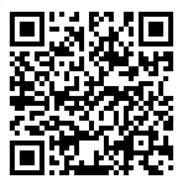